In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

In [75]:
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import  ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold

import joblib

In [26]:
df = pd.read_csv(r"E:\housePrice.csv")
df.head(10)
df.sample(5)
df["Area"] = pd.to_numeric(
    df["Area"].str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)

In [21]:
type(df)
df.columns

Index(['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address', 'Price',
       'Price(USD)'],
      dtype='str')

In [43]:
df["Area"] = pd.to_numeric(df["Area"], errors="coerce")

df.info(
    
)

<class 'pandas.DataFrame'>
Index: 3456 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3450 non-null   float64
 1   Room        3456 non-null   int64  
 2   Parking     3456 non-null   bool   
 3   Warehouse   3456 non-null   bool   
 4   Elevator    3456 non-null   bool   
 5   Address     3456 non-null   str    
 6   Price       3456 non-null   float64
 7   Price(USD)  3456 non-null   float64
dtypes: bool(3), float64(3), int64(1), str(1)
memory usage: 172.1 KB


In [28]:
df.describe()
df.shape
print(df.dtypes)
df.isnull().sum()

Area              str
Room            int64
Parking          bool
Warehouse        bool
Elevator         bool
Address           str
Price         float64
Price(USD)    float64
dtype: object


Area           0
Room           0
Parking        0
Warehouse      0
Elevator       0
Address       23
Price          0
Price(USD)     0
dtype: int64

In [30]:
df.dropna(inplace = True)
df["Parking"].value_counts(normalize = True)*100

Parking
True     84.751157
False    15.248843
Name: proportion, dtype: float64

In [34]:
df.Room.value_counts()
pd.crosstab(df.Parking , df.Room)

Room,0,1,2,3,4,5
Parking,,,,,,
False,8,243,244,26,1,5
True,2,426,1699,705,69,28


In [44]:

df.loc[df["Area"] <= 85, "Parking"].value_counts()

Parking
True     1104
False     418
Name: count, dtype: int64

In [41]:
print(df["Area"].dtype)

str


In [5]:
len(df.Address.unique()) #تعداد ادرس های یکتارا به ما میدهد

193

In [6]:
df.groupby("Room")["Price"].mean()

Room
0    7.860500e+09
1    1.703751e+09
2    3.322727e+09
3    1.092580e+10
4    2.560033e+10
5    3.373439e+10
Name: Price, dtype: float64

In [7]:
pd.set_option('display.float_format' , lambda x : '%.f' % x) #تغییر نوع نشان دادن float

In [8]:
room_parking_room_mean_df = df.groupby(["Room" , "Parking"]) ["Price"].mean().reset_index()
room_parking_room_mean_df

,Room,Parking,Price
0,0,False,9769750000
1,0,True,223500000
2,1,False,1135639592
3,1,True,2028955607
4,2,False,1501674180
5,2,True,3581513867
6,3,False,5107865385
7,3,True,11140056657
8,4,False,6200000000
9,4,True,25881492754


In [9]:
df2 = df.copy()

In [15]:
df2["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", ""),
    errors="coerce"
).map("{:,.0f}".format)
df2

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,"1,850,000,000",61667
1,60,1,True,True,True,Shahran,"1,850,000,000",61667
2,79,2,True,True,True,Pardis,"550,000,000",18333
3,95,2,True,True,True,Shahrake Qods,"902,500,000",30083
4,123,2,True,True,True,Shahrake Gharb,"7,000,000,000",233333
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,"3,500,000,000",116667
3475,83,2,True,True,True,Niavaran,"6,800,000,000",226667
3476,75,2,False,False,False,Parand,"365,000,000",12167
3477,105,2,True,True,True,Dorous,"5,600,000,000",186667


<Figure size 800x500 with 0 Axes>

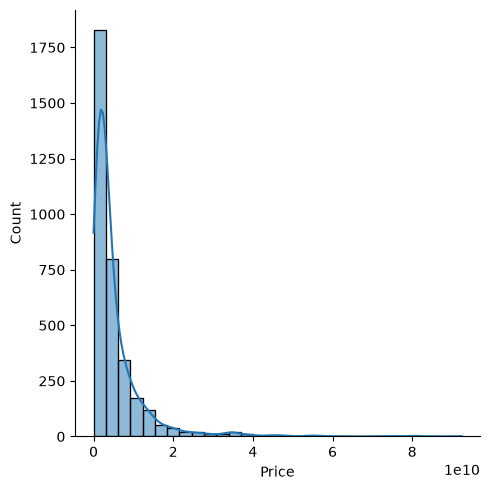

In [16]:
plt.figure(figsize = (8,5))
sns.displot(df["Price"] , bins=30 , kde = True)

<Axes: >

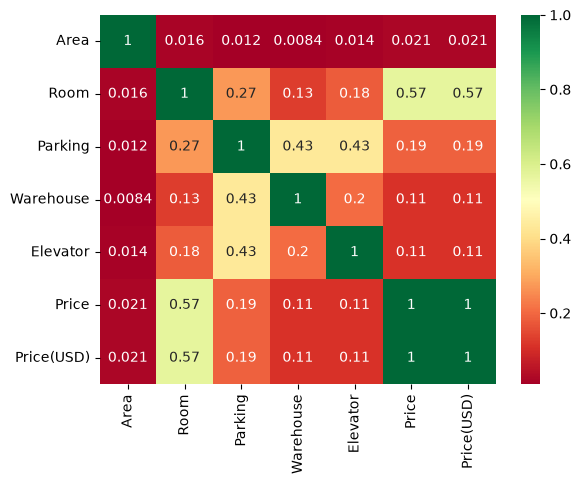

In [27]:
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="RdYlGn"
)

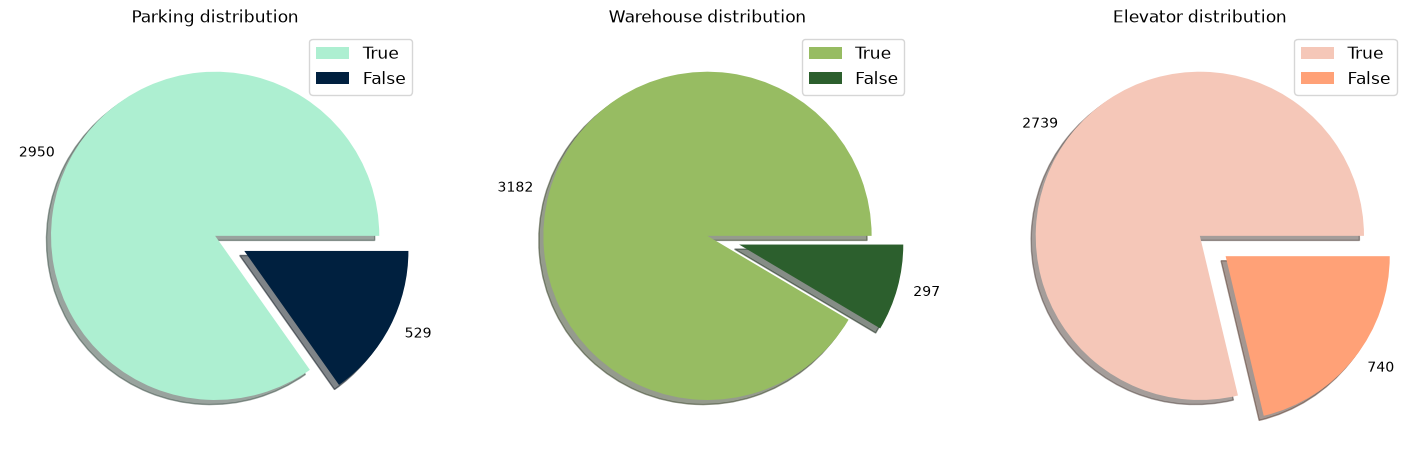

In [28]:
fig, ax = plt.subplots(ncols=3, figsize=(18,6))

colors = [['#ADEFD1FF', '#00203FFF'], ['#97BC62FF', '#2C5F2D'], ['#F5C7B8FF', '#FFA177FF']]
explode = [0, 0.2]
columns = ['Parking', 'Warehouse', 'Elevator']
for i in range(3):
        data = df[columns[i]].value_counts()
        ax[i].pie(data, labels=data.values, explode=explode, colors=colors[i], shadow=True)
        ax[i].legend(labels=data.index, fontsize='large')
        ax[i].set_title('{} distribution'.format(columns[i]))

In [35]:
df3= df["Address"].value_counts().copy()
df3[:8]


Address
Punak                     161
Pardis                    146
West Ferdows Boulevard    145
Gheitarieh                141
Shahran                   130
Saadat Abad               129
Parand                    127
Shahr-e-Ziba              109
Name: count, dtype: int64

In [36]:
df.columns

Index(['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address', 'Price',
       'Price(USD)'],
      dtype='str')

In [43]:
# df.index

df.sort_values('Price',ascending=False)[['Address']].head(20)

,Address
1707,Zaferanieh
1810,Abazar
430,Lavasan
819,Ekhtiarieh
1332,Niavaran
1694,Zafar
3051,Dorous
3107,Tajrish
831,Mahmoudieh
2394,Aqdasieh


In [44]:
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1850000000,61667
1,60,1,True,True,True,Shahran,1850000000,61667
2,79,2,True,True,True,Pardis,550000000,18333
3,95,2,True,True,True,Shahrake Qods,902500000,30083
4,123,2,True,True,True,Shahrake Gharb,7000000000,233333
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,3500000000,116667
3475,83,2,True,True,True,Niavaran,6800000000,226667
3476,75,2,False,False,False,Parand,365000000,12167
3477,105,2,True,True,True,Dorous,5600000000,186667


## مرحله قبلی فقط جمعاوری داده ها بودش ##


## این مرحله پردازش داده هستش ## 


In [45]:
##model Building ##


In [55]:
df = df.drop(columns = ['Price(USD)'])
boolean_features = ["Parking" , "Warehouse" , "Elevator"]
df[boolean_features] = df[boolean_features].astype('int64')

df.head()

KeyError: "['Price(USD)'] not found in axis"

In [57]:
print(f"Skewness of features:\n{df.skew(numeric_only=True)}")

Skewness of features:
Area        44
Room         1
Parking     -2
Warehouse   -3
Elevator    -1
Price        5
dtype: float64


<Axes: xlabel='Price'>

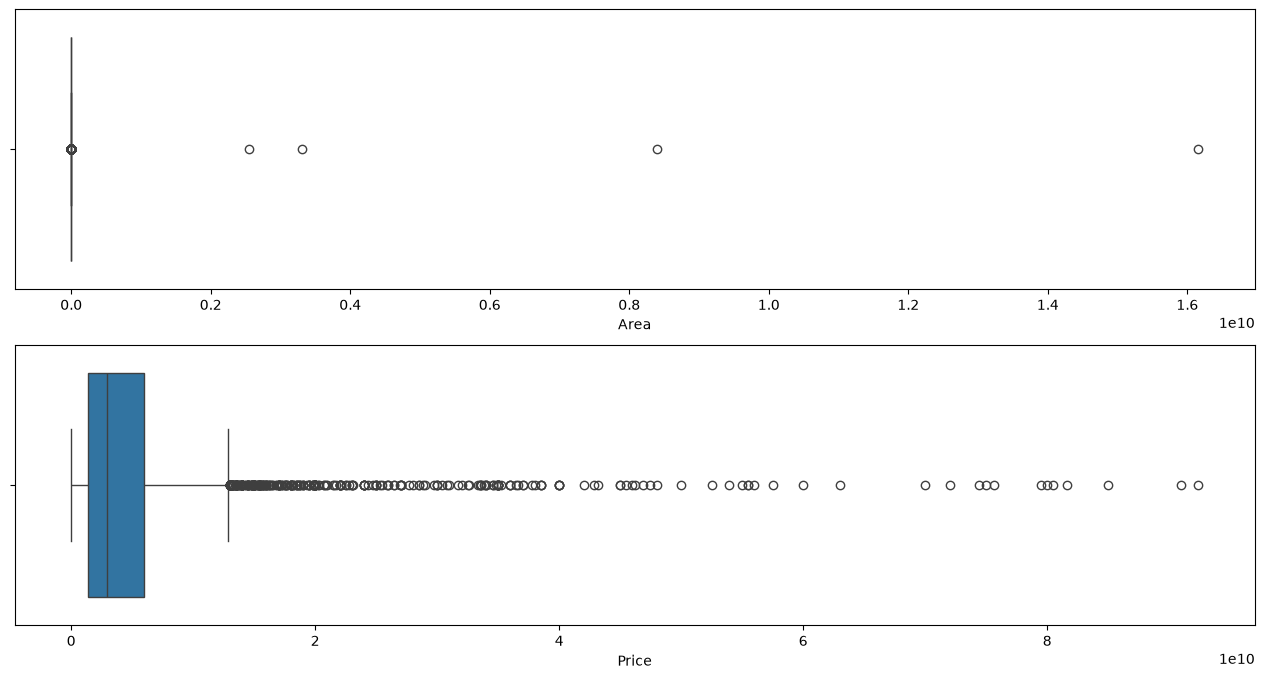

In [58]:
plt.figure(figsize = (16,8))

plt.subplot(2,1,1)
sns.boxplot(x = df['Area'])

plt.subplot(2,1,2)
sns.boxplot(x = df["Price"])

In [59]:
def lower_upper(x):
    
    Q1 = np.percentile(x, 25)
    Q3 = np.percentile(x, 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    return lower, upper

lower_area, upper_area = lower_upper(df['Area'])
lower_price, upper_price = lower_upper(df['Price'])

print(f"Lower limit for area: {lower_area:0.2f}")
print(f"Upper limit for area: {upper_area:0.2f}")
print(f"Lower limit for price: {lower_price:,}")
print(f"Upper limit for price: {upper_price:,}")

Lower limit for area: -7.50
Upper limit for area: 196.50
Lower limit for price: -5,454,375,000.0
Upper limit for price: 12,872,625,000.0


In [60]:


area_outliers = np.where(df['Area'] > upper_area)
price_outliers = np.where(df['Price'] > upper_price)
# Return the unique, sorted array of values that are in either of the two input arrays.
total_outliers = np.union1d(area_outliers, price_outliers)

print(f"Number of area outliers: {len(df.iloc[area_outliers])}")
print(f"Number of price outliers: {len(df.iloc[price_outliers])}")
print(f"Number of outliers: {len(df.iloc[total_outliers])}")



Number of area outliers: 244
Number of price outliers: 310
Number of outliers: 367


In [61]:
total_outliers

array([  25,   59,   84,  102,  146,  160,  161,  167,  174,  177,  188,
        190,  194,  196,  197,  201,  211,  216,  219,  221,  227,  235,
        236,  239,  261,  263,  265,  270,  271,  282,  284,  285,  298,
        300,  316,  328,  330,  339,  340,  341,  343,  344,  345,  346,
        347,  348,  349,  350,  352,  354,  356,  357,  363,  364,  365,
        395,  411,  412,  413,  430,  431,  437,  440,  459,  464,  497,
        513,  515,  516,  517,  526,  535,  548,  554,  560,  565,  566,
        567,  568,  570,  573,  577,  578,  579,  580,  583,  600,  601,
        611,  628,  636,  639,  641,  642,  649,  650,  653,  709,  715,
        724,  732,  733,  734,  741,  742,  743,  756,  768,  795,  806,
        807,  819,  822,  831,  837,  839,  852,  875,  879,  894,  958,
        959,  965, 1008, 1009, 1015, 1024, 1025, 1031, 1034, 1036, 1106,
       1115, 1119, 1133, 1141, 1142, 1153, 1179, 1180, 1233, 1235, 1236,
       1237, 1263, 1265, 1270, 1271, 1275, 1287, 12

In [63]:
address_dummy = pd.get_dummies(df["Address"])
df_final = df.merge(address_dummy , left_index = True , right_index = True)
df_final.drop(columns = 'Address'  , inplace = True)
df_final.head(3)

,Area,Room,Parking,Warehouse,Elevator,Price,Abazar,Abbasabad,Absard,Abuzar,...,Waterfall,West Ferdows Boulevard,West Pars,Yaftabad,Yakhchiabad,Yousef Abad,Zafar,Zaferanieh,Zargandeh,Zibadasht
0,63,1,1,1,1,1850000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,60,1,1,1,1,1850000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,79,2,1,1,1,550000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [65]:
df_final

,Area,Room,Parking,Warehouse,Elevator,Price,Abazar,Abbasabad,Absard,Abuzar,...,Waterfall,West Ferdows Boulevard,West Pars,Yaftabad,Yakhchiabad,Yousef Abad,Zafar,Zaferanieh,Zargandeh,Zibadasht
0,63,1,1,1,1,1850000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,60,1,1,1,1,1850000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,79,2,1,1,1,550000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,95,2,1,1,1,902500000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,123,2,1,1,1,7000000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3474,86,2,1,1,1,3500000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3475,83,2,1,1,1,6800000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3476,75,2,0,0,0,365000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3477,105,2,1,1,1,5600000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [67]:
X = df_final.drop(columns = 'Price')
y = df_final['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)
print(f"shape of x train: {X_train.shape}")
print(f"shape of y train: {y_train.shape}")
print(f"shape of x test: {X_test.shape}")
print(f"shape of y train: {y_test.shape}")

shape of x train: (2783, 197)
shape of y train: (2783,)
shape of x test: (696, 197)
shape of y train: (696,)


In [78]:


def parameter_finder (model, parameters):
    
    start = time.time()
    
    grid = GridSearchCV(model, 
                        param_grid = parameters, 
                        refit = True, 
                        cv = KFold(shuffle = True, random_state = 1), 
                        n_jobs = -1)
    grid_fit = grid.fit(X_train, y_train)
    y_train_pred = grid_fit.predict(X_train)
    y_pred = grid_fit.predict(X_test)
    
    train_score =grid_fit.score(X_train, y_train)
    test_score = grid_fit.score(X_test, y_test)
    RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
    
    model_name = str(model).split('(')[0]
    
    end = time.time()
    
    print(f"The best parameters for {model_name} model is: {grid_fit.best_params_}")
    print("--" * 10)
    print(f"(R2 score) in the training set is {train_score:0.2%} for {model_name} model.")
    print(f"(R2 score) in the testing set is {test_score:0.2%} for {model_name} model.")
    print(f"RMSE is {RMSE:,} for {model_name} model.")
    print("--" * 10)
    print(f"Runtime of the program is: {end - start:0.2f}")
    
       
    return train_score, test_score, RMSE



In [77]:

lr = LinearRegression(n_jobs = -1)

lr_train_score, lr_test_score, lr_RMSE = parameter_finder(lr, {})



The best parameters for LinearRegression model is: {}
--------------------
(R2 score) in the training set is 0.06% for LinearRegression model.
(R2 score) in the testing set is -0.15% for LinearRegression model.
RMSE is 7,588,050,396.307471 for LinearRegression model.
--------------------
Runtime of the program is: 11.31


In [76]:


ridge = Ridge(random_state = 1) # Linear least squares with l2 regularization.
param_ridge = {'alpha': [0.001, 0.01, 0.1, 1, 10]}

ridge_train_score, ridge_test_score, ridge_RMSE = parameter_finder(ridge, param_ridge)



The best parameters for Ridge model is: {'alpha': 1}
--------------------
(R2 score) in the training set is 60.74% for Ridge model.
(R2 score) in the testing set is 51.48% for Ridge model.
RMSE is 5,281,634,114.436807 for Ridge model.
--------------------
Runtime of the program is: 18.75


C:\Users\rayaneh valiasr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.959070072514109e-21.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


In [79]:


lasso = Lasso(random_state = 1) # Linear Model trained with L1 prior as regularizer.
param_lasso = {'alpha': [0.001, 0.01, 0.1, 1, 10]}

lasso_train_score, lasso_test_score, lasso_RMSE = parameter_finder(lasso, param_lasso)



The best parameters for Lasso model is: {'alpha': 10}
--------------------
(R2 score) in the training set is 61.63% for Lasso model.
(R2 score) in the testing set is 50.32% for Lasso model.
RMSE is 5,344,504,145.977632 for Lasso model.
--------------------
Runtime of the program is: 17.84


C:\Users\rayaneh valiasr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.609267e+22, tolerance: 1.881e+19
  model = cd_fast.enet_coordinate_descent(


In [80]:
eln = ElasticNet(random_state = 1) # Linear regression with combined L1 and L2 priors as regularizer.
param_eln = {'alpha': [0.001, 0.01, 0.1, 1, 10],
            'l1_ratio': [0.3, 0.4, 0.5, 0.6, 0.7]}

eln_train_score, eln_test_score, eln_RMSE = parameter_finder(eln, param_eln)

The best parameters for ElasticNet model is: {'alpha': 0.001, 'l1_ratio': 0.5}
--------------------
(R2 score) in the training set is 60.35% for ElasticNet model.
(R2 score) in the testing set is 51.67% for ElasticNet model.
RMSE is 5,270,942,578.83519 for ElasticNet model.
--------------------
Runtime of the program is: 70.51


C:\Users\rayaneh valiasr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.977425e+22, tolerance: 1.881e+19
  model = cd_fast.enet_coordinate_descent(


In [81]:
dtr = DecisionTreeRegressor(random_state = 1)
param_dtr = {'min_samples_split': [2, 3, 4, 5],
            'min_samples_leaf': [1, 2, 3]}

dtr_train_score, dtr_test_score, dtr_RMSE = parameter_finder(dtr, param_dtr)

The best parameters for DecisionTreeRegressor model is: {'min_samples_leaf': 3, 'min_samples_split': 2}
--------------------
(R2 score) in the training set is 83.75% for DecisionTreeRegressor model.
(R2 score) in the testing set is 80.53% for DecisionTreeRegressor model.
RMSE is 3,346,045,065.404804 for DecisionTreeRegressor model.
--------------------
Runtime of the program is: 1.77


In [82]:
rfr = RandomForestRegressor(random_state = 1, n_jobs = -1)
param_rfr = {'min_samples_split': [2, 3, 4, 5],
            'min_samples_leaf': [1, 2, 3]}

rfr_train_score, rfr_test_score, rfr_RMSE = parameter_finder(rfr, param_rfr)

The best parameters for RandomForestRegressor model is: {'min_samples_leaf': 1, 'min_samples_split': 5}
--------------------
(R2 score) in the training set is 93.46% for RandomForestRegressor model.
(R2 score) in the testing set is 81.55% for RandomForestRegressor model.
RMSE is 3,257,035,063.2697735 for RandomForestRegressor model.
--------------------
Runtime of the program is: 68.74


In [83]:
knr = KNeighborsRegressor(n_jobs = -1)
param_knr = {'n_neighbors': [5, 10, 15, 20],
            'weights': ['uniform', 'distance']}

knr_train_score, knr_test_score, knr_RMSE = parameter_finder(knr, param_knr)

The best parameters for KNeighborsRegressor model is: {'n_neighbors': 20, 'weights': 'uniform'}
--------------------
(R2 score) in the training set is 63.11% for KNeighborsRegressor model.
(R2 score) in the testing set is 60.42% for KNeighborsRegressor model.
RMSE is 4,770,358,165.230724 for KNeighborsRegressor model.
--------------------
Runtime of the program is: 5.19


In [84]:

xgboost = XGBRegressor(n_jobs = -1)
param_xgboost = {'n_estimators': [100,300],
             'learning_rate': [0.1,0.05],
             'subsample': [0.75],
             'colsample_bytree': [1],
             'max_depth': [3,4,5],
             'gamma': [0]}

xgboost_train_score, xgboost_test_score, xgboost_RMSE = parameter_finder(xgboost, param_xgboost)



The best parameters for XGBRegressor model is: {'colsample_bytree': 1, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.75}
--------------------
(R2 score) in the training set is 94.86% for XGBRegressor model.
(R2 score) in the testing set is 87.39% for XGBRegressor model.
RMSE is 2,692,220,662.684503 for XGBRegressor model.
--------------------
Runtime of the program is: 18.42


In [85]:


models_score = pd.DataFrame({'Training score': [lr_train_score, ridge_train_score, lasso_train_score, eln_train_score, dtr_train_score, rfr_train_score, knr_train_score,xgboost_train_score],
                             'Testing score': [lr_test_score, ridge_test_score, lasso_test_score, eln_test_score, dtr_test_score, rfr_test_score, knr_test_score,xgboost_test_score],
                             'RMSE': [lr_RMSE, ridge_RMSE, lasso_RMSE, eln_RMSE, dtr_RMSE, rfr_RMSE, knr_RMSE,xgboost_RMSE]},
                             index = ['LinearRegression', 'Ridge', 'Lasso','ElasticNet', 'DecisionTreeRegressor', 'RandomForestRegressor', 'KNeighborsRegressor','XGBoostRegressor'])

models_score



,Training score,Testing score,RMSE
LinearRegression,0,-0,7588050396
Ridge,1,1,5281634114
Lasso,1,1,5344504146
ElasticNet,1,1,5270942579
DecisionTreeRegressor,1,1,3346045065
RandomForestRegressor,1,1,3257035063
KNeighborsRegressor,1,1,4770358165
XGBoostRegressor,1,1,2692220663


C:\Users\rayaneh valiasr\AppData\Local\Temp\ipykernel_5320\3359439921.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = list(models_score.index), y = models_score['RMSE']/1000000000, alpha = 0.7, palette='Greens_r')


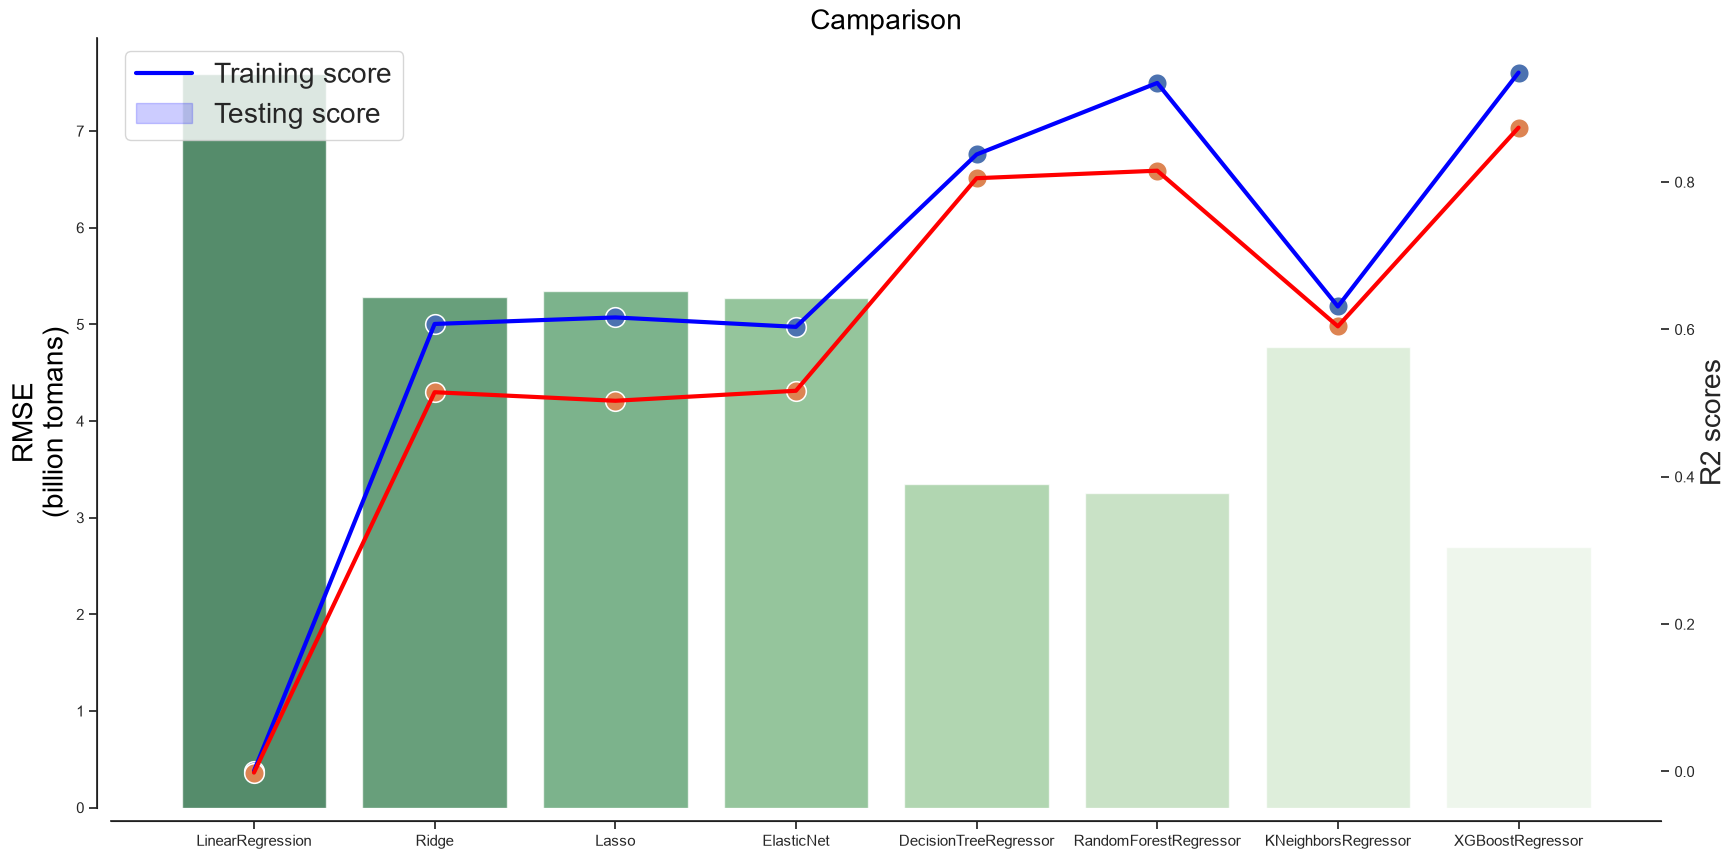

In [86]:


fig, ax = plt.subplots(figsize=(20,10))

sns.set(style='white')

ax.set_title("Camparison", fontsize = 20)

ax = sns.barplot(x = list(models_score.index), y = models_score['RMSE']/1000000000, alpha = 0.7, palette='Greens_r')

ax.set_ylabel("RMSE\n(billion tomans)", fontsize = 20)

sec_ax = ax.twinx()

sec_ax = sns.lineplot(x = list(models_score.index), y = models_score['Training score'], linewidth = 3, color = 'blue')
sec_ax = sns.scatterplot(x = list(models_score.index), y = models_score['Training score'], s = 200)

sec_ax = sns.lineplot(x = list(models_score.index), y = models_score['Testing score'], linewidth = 3, color = 'red')
sec_ax = sns.scatterplot(x = list(models_score.index), y = models_score['Testing score'], s = 200)

sec_ax.set_ylabel("R2 scores", fontsize = 20)

sec_ax.legend(labels = ['Training score', 'Testing score'], fontsize = 20)


sns.despine(offset = 10)

plt.show()

